> **Portfolio maintenance note:** The dataset path was made portable and the chi-square contingency table was corrected to exclude totals. Original analysis and other stored outputs are retained; rerun all cells to refresh the complete notebook.

<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300" height="100"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200" height="100"/>
</p></center>

<center><font size=10>Decision Making with Business Statistics</center></font>
<center><font size=5>Week 4: Project: E-News Express</font></center>

## Define Problem Statement and Objectives

## **Business Statement and Objectives**


**Business Statement**

The advent of e-news, or electronic news, portals has offered us a great opportunity to quickly get updates on the day-to-day events occurring globally. The information on these portals is retrieved electronically from online databases, processed using a variety of software, and then transmitted to the users. There are multiple advantages of transmitting new electronically, like faster access to the content and the ability to utilize different technologies such as audio, graphics, video, and other interactive elements that are either not being used or aren’t common yet in traditional newspapers.

E-news Express, an online news portal, aims to expand its business by acquiring new subscribers. With every visitor to the website taking certain actions based on their interest, the company plans to analyze these actions to understand user interests and determine how to drive better engagement. The executives at E-news Express are of the opinion that there has been a decline in new monthly subscribers compared to the past year because the current webpage is not designed well enough in terms of the outline & recommended content to keep customers engaged long enough to make a decision to subscribe.

**Business Objectives**

The design team of the company has researched and created a new landing page that has a new outline & more relevant content shown compared to the old page. In order to test the effectiveness of the new landing page in gathering new subscribers, the Data Science team conducted an experiment by randomly selecting 100 users and dividing them equally into two groups. The existing landing page was served to the first group (control group) and the new landing page to the second group (treatment group). Data regarding the interaction of users in both groups with the two versions of the landing page was collected. Being a data scientist in E-news Express, you have been asked to explore the data and perform a statistical analysis (at a significance level of 5%) to determine the effectiveness of the new landing page in gathering new subscribers for the news portal by answering the following questions:

Do the users spend more time on the new landing page than on the existing landing page?

Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?

Does the converted status depend on the preferred language? [Hint: Create a contingency table using the pandas.crosstab() function]

Is the time spent on the new page the same for the different language users?

1.   Do the users spend more time on the new landing page than on the existing landing page?
2.   Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?
1.   Does the converted status depend on the preferred language?
2.   Is the time spent on the new page the same for the different language users?





##**Import all the necessary libraries**

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scipy==1.11.4 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 55.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [ ]:
# Connecting to the libraries listed below
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns


##**Loading the Data and Reading the Data into a DataFrame**

*   To load the `abtest.csv` file from Google Drive, we first need to mount Google Drive to this Colab notebook. Then, you will need to update the `file_path` variable with the correct path to your CSV file in your Google Drive.

**Mount Google Drive**


In [ ]:
# Mounting Google drive to colab notebook
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Import the data in Google Drive and create the data frame**

In [ ]:
# Load the dataset from the same folder as this notebook.
# In Google Colab, upload abtest.csv to the session first.
import pandas as pd
df = pd.read_csv('abtest.csv')

**Data Description**

The data contains information regarding the interaction of users in both groups with the two versions of the landing page.

*   user_id - Unique user ID of the person visiting the website
*   group - Whether the user belongs to the first group (control) or the second group (treatment)
*   landing_page - Whether the landing page is new or old
*   time_spent_on_the_page - Time (in minutes) spent by the user on the landing page
*   converted - Whether the user gets converted to a subscriber of the news portal or not
*   language_preferred - Language chosen by the user to view the landing page


##**Exploring and understanding the dataset**

- Data Overview
  - Viewing the first and last few rows of the dataset
  - Checking the shape of the dataset
  - Getting the statistical summary for the variables
- Check for missing values
- Check for duplicates

**Checking the first and last rows of the dataset**

In [ ]:
# Viewing the first rows of the dataset
df.head()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


In [ ]:
# Viewing the Last rows of the dataset
df.tail()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
95,546446,treatment,new,5.15,no,Spanish
96,546544,control,old,6.52,yes,English
97,546472,treatment,new,7.07,yes,Spanish
98,546481,treatment,new,6.20,yes,Spanish
99,546483,treatment,new,5.86,yes,English


**Viewing the shape of the dataset**

In [ ]:
# Checking the shape of the dataset
df.shape

(100, 6)

*The dataset has 100 rows of data and 6 columns.*

**Viewing the Data Types of the dataset**

In [ ]:
# Checking the datatypes within the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 100 non-null    int64  
 1   group                   100 non-null    object 
 2   landing_page            100 non-null    object 
 3   time_spent_on_the_page  100 non-null    float64
 4   converted               100 non-null    object 
 5   language_preferred      100 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 4.8+ KB


*All data is present within the dataset because the non-null counts are equal to the number of entries (100). A check will be performed in the next step to validate this claim.*

**Checking for missing values within the dataset**

In [ ]:
# Checking if data is missing
df.isnull().sum()

,0
user_id,0
group,0
landing_page,0
time_spent_on_the_page,0
converted,0
language_preferred,0


*There are no missing values in the dataset.*

**Checking for duplicate User Id entries in the dataset**

In [ ]:
# Find duplicate entries based on User id
df.duplicated(['user_id']).sum()

np.int64(0)

*There are no duplicated entries for User ids.*

In [ ]:
# Getting the statistical summary of the dataset
df.describe()

,user_id,time_spent_on_the_page
count,100.000000,100.000000
mean,546517.000000,5.377800
std,52.295779,2.378166
min,546443.000000,0.190000
25%,546467.750000,3.880000
50%,546492.500000,5.415000
75%,546567.250000,7.022500
max,546592.000000,10.710000


*   The mean of the dataset is 5.377800.
*   The standard deviation of the dataset is 2.378166.
*   The median of the dataset is 5.41500.

*Since the mean and median are close in value, the distribution may be roughly symmetric; not heavily skewed to the right or left.*




##**Extracting insights using Exploratory Data Analysis - Univariate Analysis**

**1.  Finding unique items**

*   Checking the number of unique User IDs



In [ ]:
# check unique user IDs
df['user_id'].nunique()

100

*There are 100 unique User Ids.  This suggests that there are no duplicate entries in the User Id column.*

**2.  Checking the number of Groups**

In [ ]:
# check unique group
df['group'].unique()

array(['control', 'treatment'], dtype=object)

*There are 2 unique Groups, control and treatment.*

In [ ]:
df['group'].value_counts(normalize=False)

,count
group,
control,50
treatment,50


Users in the control group  50
Users in the treatment group  50


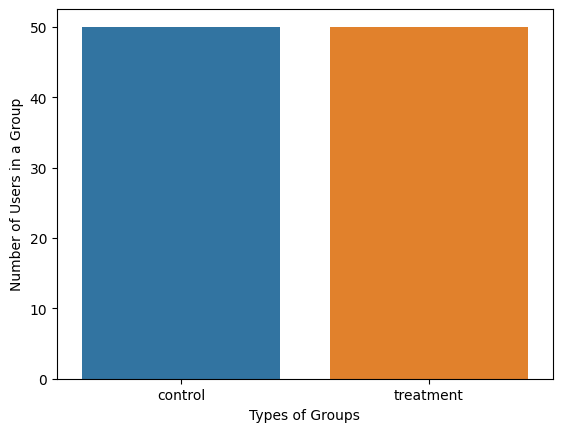

In [ ]:
sns.countplot(data=df,x='group',hue='group')
plt.xlabel('Types of Groups')
plt.ylabel('Number of Users in a Group')
print('Users in the control group ',    df['group'].value_counts().iloc[0])
print('Users in the treatment group ', df['group'].value_counts().iloc[1])
plt.show()

*There are 2 groups: Treatment and control*

**3.  Checking the number of choices for the Landing Page**

In [ ]:
# check unique landing page
df['landing_page'].unique()

array(['old', 'new'], dtype=object)

In [ ]:
df['landing_page'].value_counts(normalize=False)

,count
landing_page,
old,50
new,50


Users on the old landing page  50
Users on the new landing page  50


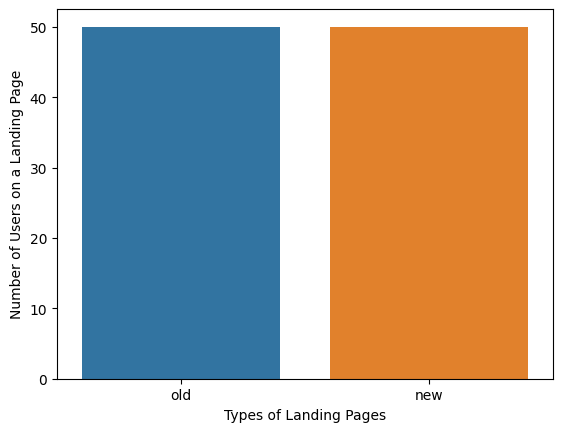

In [ ]:
#Observation on Landing Page
sns.countplot(data=df,x='landing_page',hue='landing_page')
plt.xlabel('Types of Landing Pages')
plt.ylabel('Number of Users on a Landing Page')
print('Users on the old landing page ', df['landing_page'].value_counts().iloc[0])
print('Users on the new landing page ', df['landing_page'].value_counts().iloc[1])
plt.show()

*There are 2 types of landing pages, 'old' and 'new'.  Each landing page had 50 users view those pages.*

**4.  Observation on the Times Spent on the Landing Pages**

In [ ]:
df['time_spent_on_the_page'].value_counts(normalize=False)

,count
time_spent_on_the_page,
4.75,2
5.86,2
3.88,2
0.40,2
7.16,2
...,...
3.05,1
5.15,1
6.52,1


*Some users were on the landing pages for the same period of time.*


Sample mean: 5.38


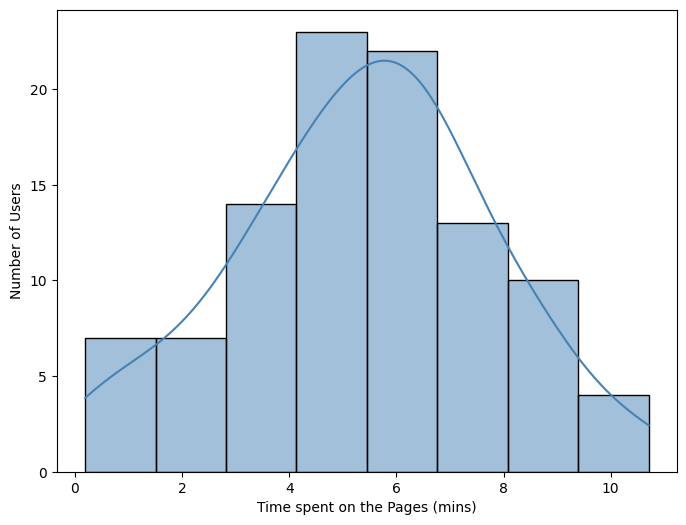

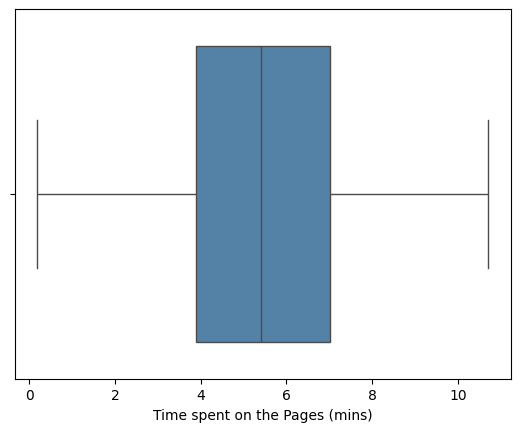

In [ ]:
# Display the distribution of time that users spent on the landing pages.
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(data=df, x='time_spent_on_the_page', color='steelblue', kde=True, ax=ax)
plt.xlabel('Time spent on the Pages (mins)')
plt.ylabel('Number of Users')
print('Sample mean:', np.round(df.time_spent_on_the_page.mean(),2))
plt.show()

# Display the amount of time users spent within quartiles 1 to 3
sns.boxplot(data=df,x='time_spent_on_the_page', color='steelblue')
plt.xlabel('Time spent on the Pages (mins)')
plt.show()

*   The histogram shows that the distribution of time spent on the landing pages is roughly symmetric (not not equal but more uniformed).

*   The boxplot shows that 50% of the users spent about 4 to 7 minutes on either the old or new landing pages.

**5.  Observations on the choices for converted status**

In [ ]:
# Check the unique values for the converted status
df['converted'].unique()

array(['no', 'yes'], dtype=object)

In [ ]:
# Display the number of users by converted status
df['converted'].value_counts(normalize=False)

,count
converted,
yes,54
no,46


Converted Status - No   54
Converted Status - Yes  46


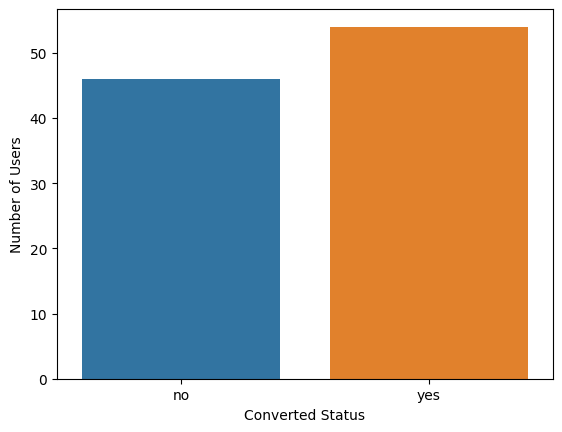

In [ ]:
# Create a countplot to display the number of users who converted or not.
sns.countplot(data=df,x='converted',hue='converted')
plt.xlabel('Converted Status')
plt.ylabel('Number of Users')
print('Converted Status - No  ', df['converted'].value_counts().iloc[0])
print('Converted Status - Yes ', df['converted'].value_counts().iloc[1])
plt.show()

*There are 2 converstion statuses, 'no' and 'yes'; more users converted over to a subscription for the news portal.*

**6.  Observations on the language preferred**

In [ ]:
# Display the different preferred languages
df['language_preferred'].unique()

array(['Spanish', 'English', 'French'], dtype=object)

In [ ]:
df['language_preferred'].value_counts(normalize=False)

,count
language_preferred,
Spanish,34
French,34
English,32


Users who preferred Spanish  34
Users who preferred English  32
Users who preferred French   34


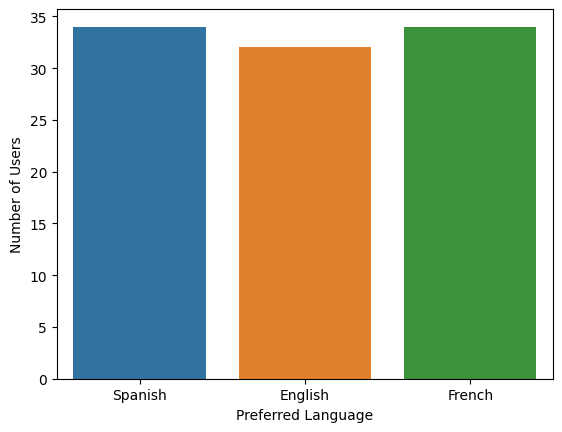

In [ ]:
sns.countplot(data=df,x='language_preferred',hue='language_preferred')
plt.xlabel('Preferred Language')
plt.ylabel('Number of Users')
lang_counts = df['language_preferred'].value_counts()
print('Users who preferred Spanish ', lang_counts['Spanish'])
print('Users who preferred English ', lang_counts['English'])
print('Users who preferred French  ', lang_counts['French'])
plt.show()

*There are 3 preferred languages: English, French, and Spanish. There is not much difference in the preference of language that the users have selected.*

##**Extracting insights using Exploratory Data Analysis - Bivariate Analysis**

Based on the objectives, the bivariate analysis will be focused around the questions in the objective.  The areas of focus will be finding a relationship between:


1.   The landing page vs the time spent on the pages
2.   The conversion status vs the time spent on the pages
1.   The preferred language vs the time spent on the pages







**1.   The landing page vs the time spent on the pages**

The mean time spent on the old landing page is: 4.53
The mean time spent on the new landing page is: 6.22


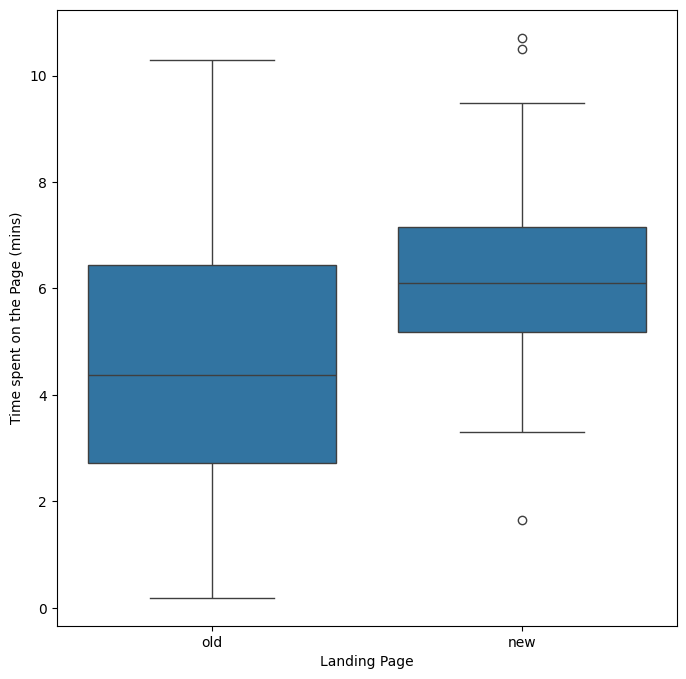

In [ ]:
# Landing page vs. Time (Comparing the means by group)
plt.figure(figsize=(8,8))
sns.boxplot(data=df,x='landing_page',y='time_spent_on_the_page')
plt.xlabel('Landing Page')
plt.ylabel('Time spent on the Page (mins)')
print('The mean time spent on the old landing page is:', round(df[df['landing_page'] == 'old']['time_spent_on_the_page'].mean(),2                                                                ))
print('The mean time spent on the new landing page is:', round(df[df['landing_page'] == 'new']['time_spent_on_the_page'].mean(),2))
plt.show()

*There is a larger variation in time that users spent on the old page vs the new page. However, based on the boxplot, 50% of the users in the treatment group spent more time on the new landing page (between 5 and 7 minutes),than 50% of the users in the control group (between 2.75 and 6.25 minutes).*

**2.   The conversion status vs the time spent on the pages**

The mean time of the users who did not convert: 3.92
The mean time of the users who converted: 6.62


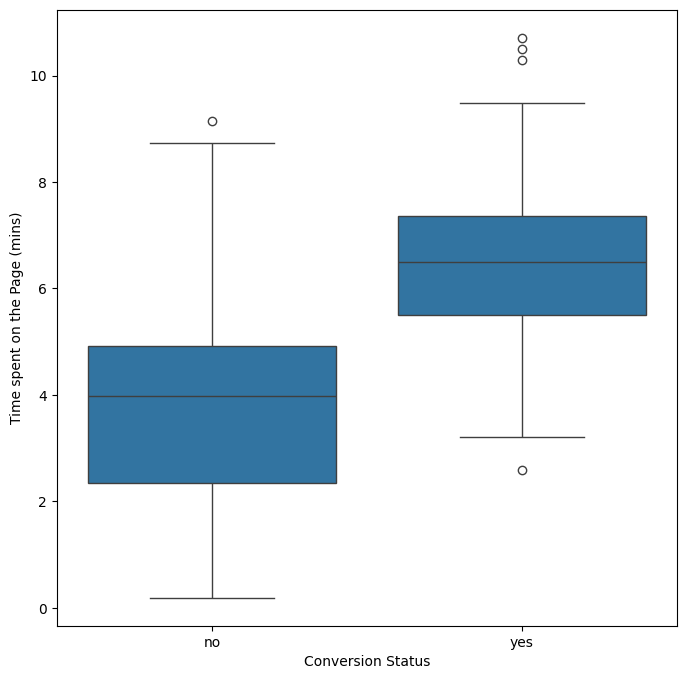

In [ ]:
# Conversion vs. Time (Comparing the means by group)
plt.figure(figsize=(8,8))
sns.boxplot(data=df,x='converted',y='time_spent_on_the_page')
plt.xlabel('Conversion Status')
plt.ylabel('Time spent on the Page (mins)')
print('The mean time of the users who did not convert:', round(df[df['converted'] == 'no']['time_spent_on_the_page'].mean(),2))
print('The mean time of the users who converted:', round(df[df['converted'] == 'yes']['time_spent_on_the_page'].mean(),2))
plt.show()

*There is a larger variation in time that non-converted users spent on the landing pages vs the converted users. However, based on the boxplot, 50% of the converted users in the treatment group and the control group spent more time on the landing pages (between 5.5 and 7.5 minutes),than 50% of the non-coverted users in the control group and the treatment group (between 2.75 and 5 minutes).*

**3.   The preferred language vs the time spent on the pages**

The mean time spent on the old landing page for users who preferred Spanish is: 5.33
The mean time spent on the new landing page for users who preferred English is: 5.56
The mean time spent on the new landing page for users who preferred French  is: 5.25


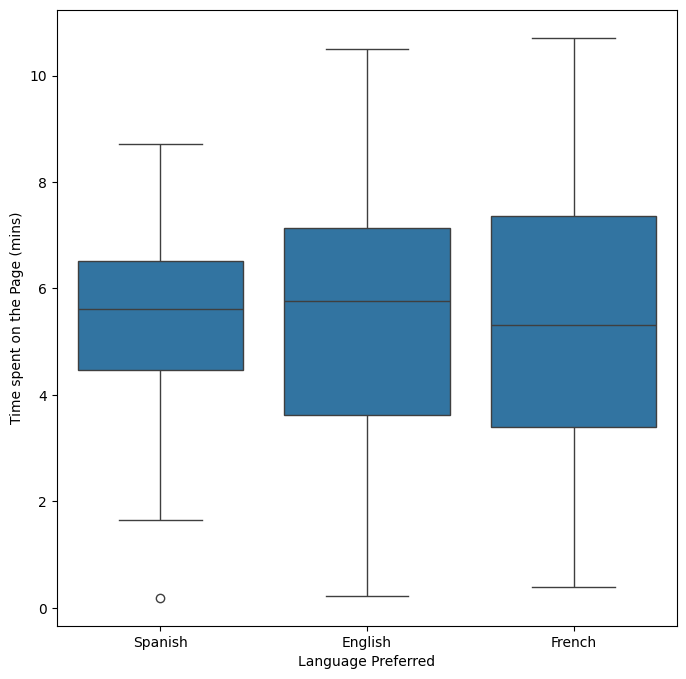

In [ ]:
# Language Preferred vs. Time (Comparing the mean by groups)
plt.figure(figsize=(8,8))
sns.boxplot(data=df,x='language_preferred',y='time_spent_on_the_page')
plt.xlabel('Language Preferred')
plt.ylabel('Time spent on the Page (mins)')
print('The mean time spent on the old landing page for users who preferred Spanish is:', round(df[df['language_preferred'] == 'Spanish']['time_spent_on_the_page'].mean(),2))
print('The mean time spent on the new landing page for users who preferred English is:', round(df[df['language_preferred'] == 'English']['time_spent_on_the_page'].mean(),2))
print('The mean time spent on the new landing page for users who preferred French  is:', round(df[df['language_preferred'] == 'French']['time_spent_on_the_page'].mean(),2))
plt.show()

*There is a larger variation in time that users preferring either English or French spent on the landing pages. However, based on the boxplot, users preferring English had a slight higher mean spending time on the landing pages, compared to users preferring French or Spanish.*

##Business Objectives - Questions

##1. Do the users spend more time on the new landing page than the existing landing page?

**Step 1.  Perform Visual Analysis**

*Based on the question, will use the box plot to compare the the mean of the users who spend time on the new landing page to those users who spend time on the old landing page.*

The mean time spent on the old landing page is: 4.53
The mean time spent on the new landing page is: 6.22


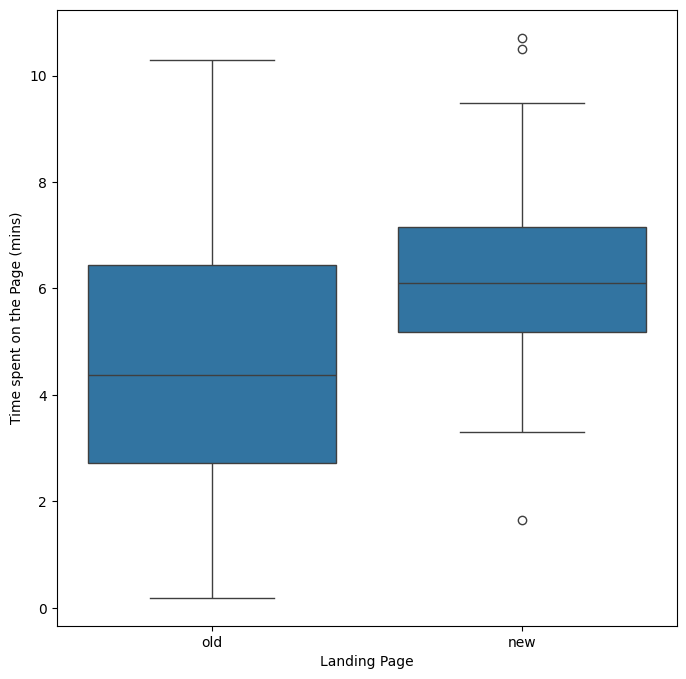

In [ ]:
# Landing page vs. Time (Comparing the means by group)
plt.figure(figsize=(8,8))
sns.boxplot(data=df,x='landing_page',y='time_spent_on_the_page')
plt.xlabel('Landing Page')
plt.ylabel('Time spent on the Page (mins)')
print('The mean time spent on the old landing page is:', round(df[df['landing_page'] == 'old']['time_spent_on_the_page'].mean(),2))
print('The mean time spent on the new landing page is:', round(df[df['landing_page'] == 'new']['time_spent_on_the_page'].mean(),2))
plt.show()

**Step 2: Define the null and alternate hypothesis**

H$_o$: $\mu$$_{new}$  $\leq$  $\mu$$_{old}$; Users are spending the same or less time on the new page than the existing page.

H$_a$: $\mu$$_{new}$  $>$  $\mu$$_{old}$; Users are spending more time on the new page than the exi2sting page.

**Step 3: Select Appropriate test - One-tail T-test**

*Because we are testing if the new users spend more time on the landing page than the old users, we will be using the One-tail test because of the keyword "more" and it shows the level of significance going in one direction. The image below captures the path that is taken to get to the selected test.*

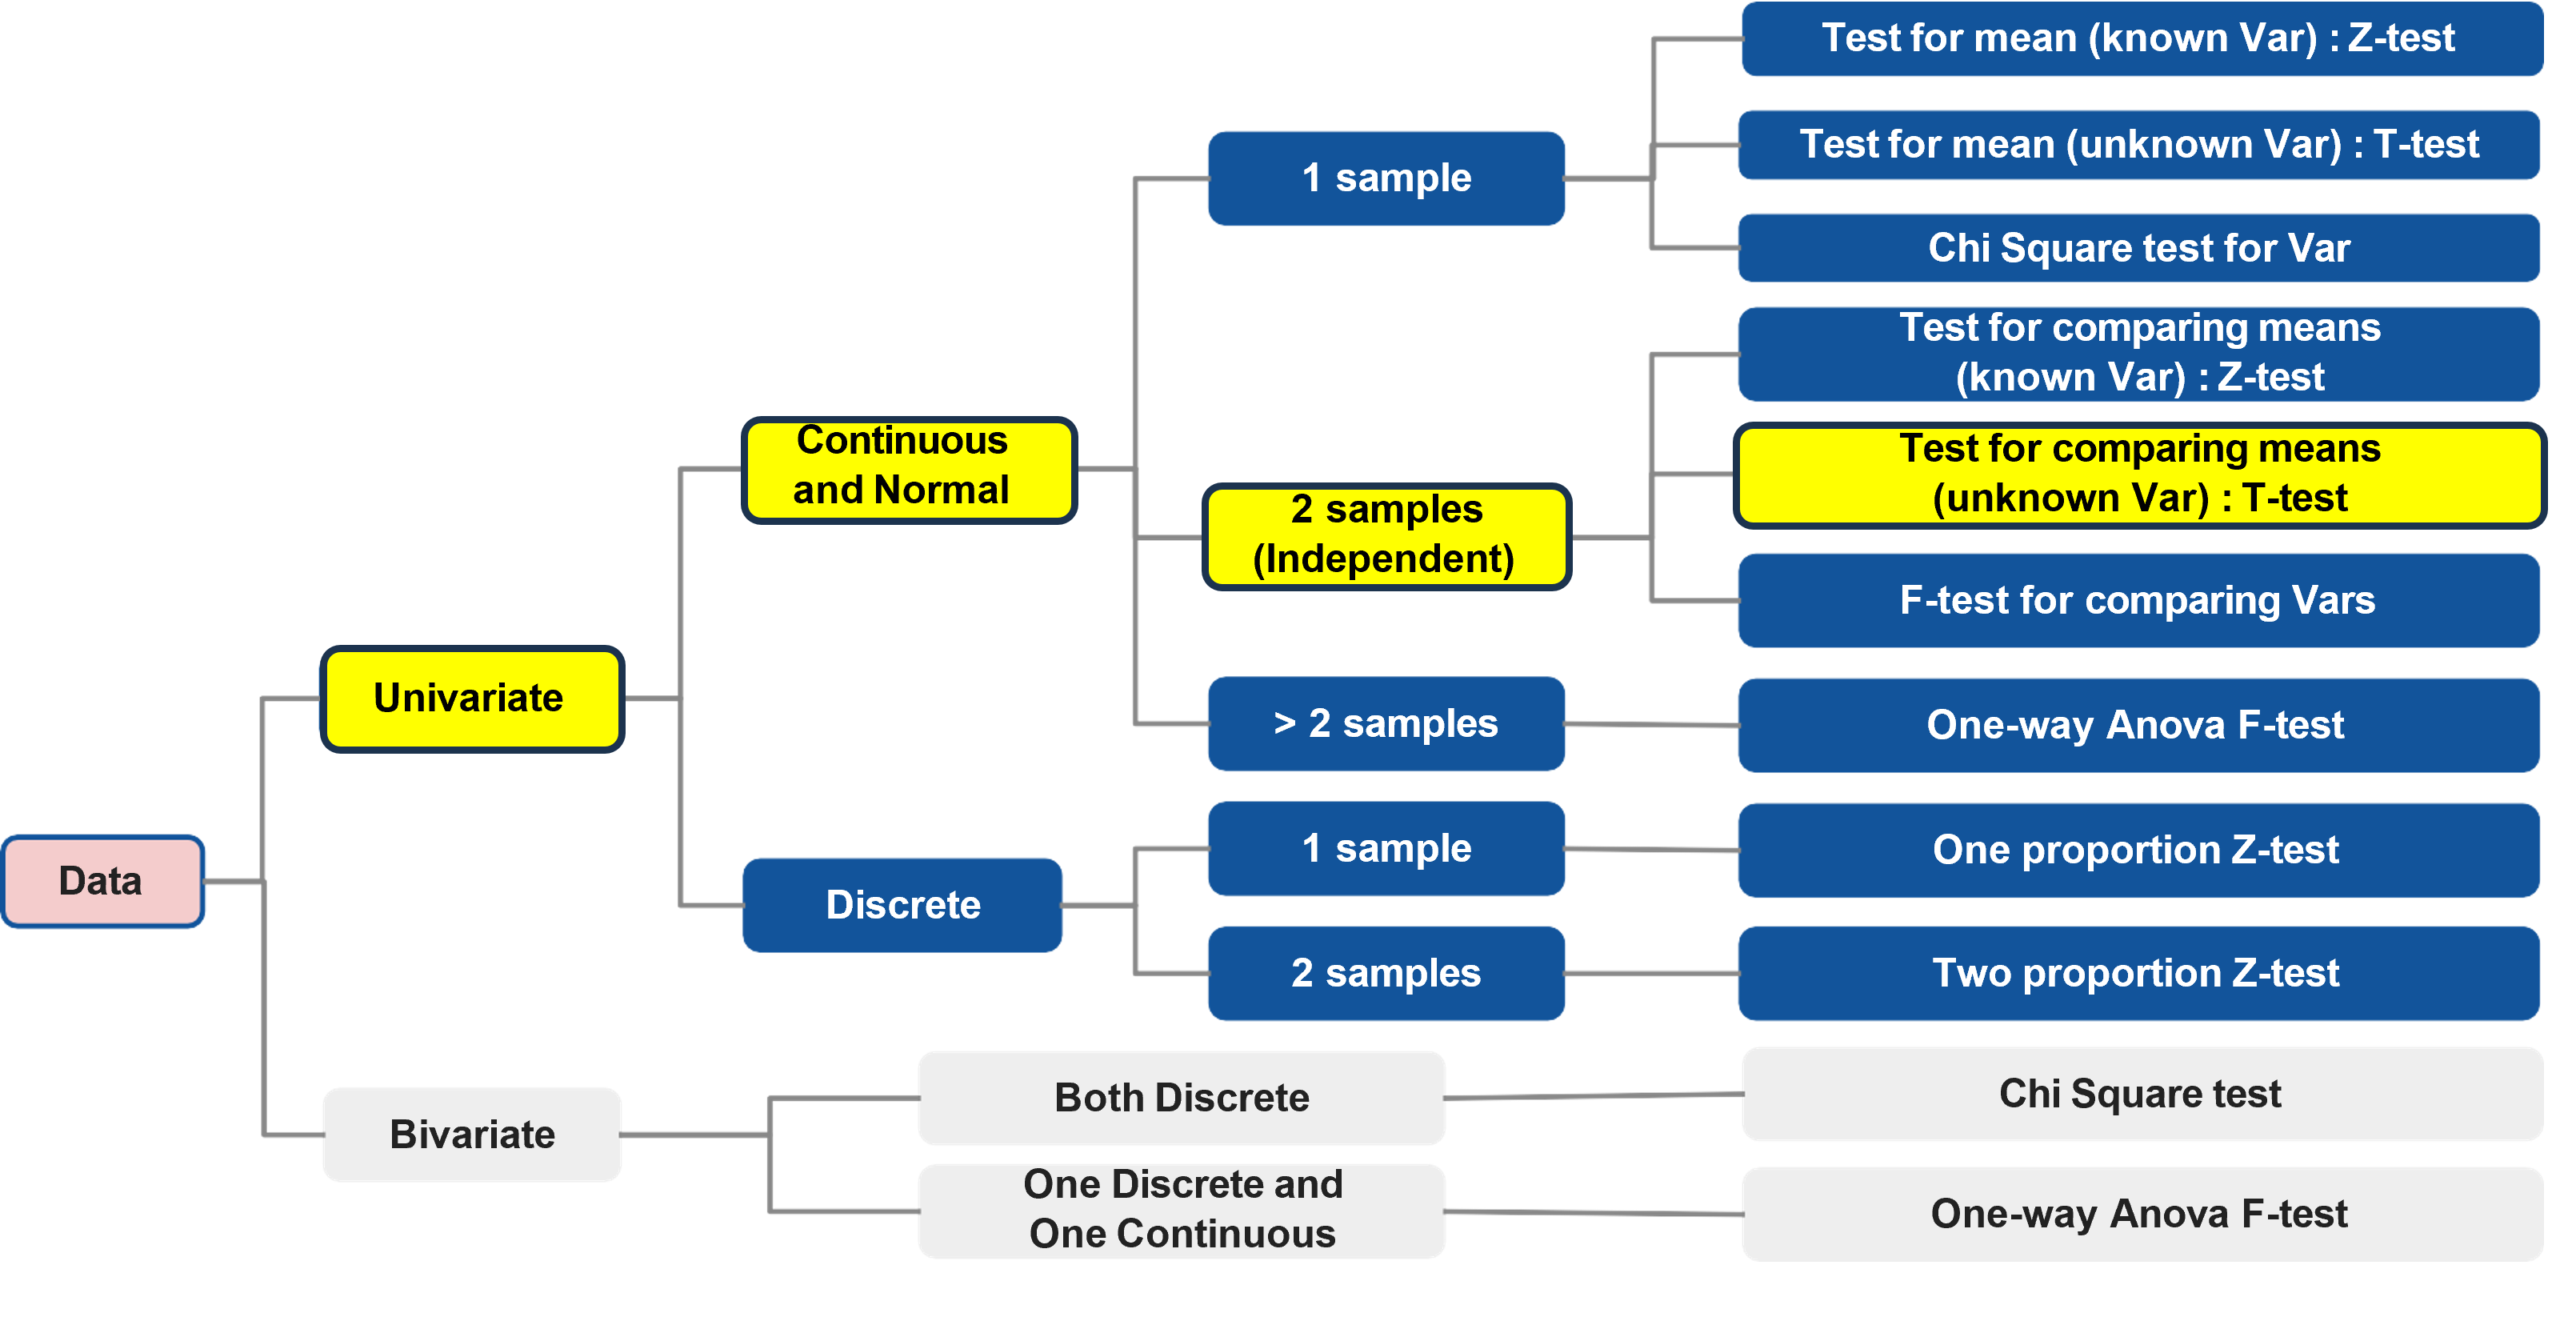

**Step 4: Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

**Step 5: Collect and prepare data**

In [ ]:
# Finding the Standard deviation for the amount of time that users spent on the old landing page and the new landing page.

# create subsetted data frame for new landing page users
time_spent_new = df[df['landing_page'] == 'new']['time_spent_on_the_page']

# create subsetted data frame for old landing page users
time_spent_old = df[df['landing_page'] == 'old']['time_spent_on_the_page']

print('The sample standard deviation of the time spent on the new page for new users is:', round(time_spent_new.std(),2))
print('The sample standard deviation of the time spent on the new page for old users is:', round(time_spent_old.std(),2))

The sample standard deviation of the time spent on the new page for new users is: 1.82
The sample standard deviation of the time spent on the new page for old users is: 2.58


**Step 6: Calculate the p-value**

In [ ]:
from scipy.stats import ttest_ind

# write the code to calculate the p-value
test_stat, p_value = ttest_ind(time_spent_new, time_spent_old, equal_var = False, alternative = 'greater')
print('The p-value is', p_value)
print('The test statistic is', test_stat)

The p-value is 0.0001392381225166549
The test statistic is 3.7867702694199856


Sample mean: 5.38


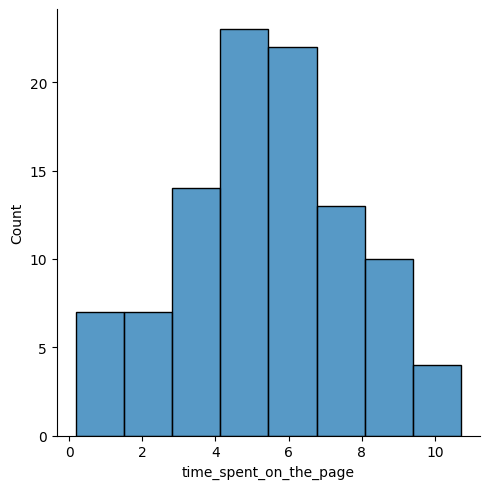

In [ ]:
# plot the distribution plot of engagement-time
print('Sample mean:', np.round(df.time_spent_on_the_page.mean(),2))
sns.displot(df.time_spent_on_the_page)
plt.show()

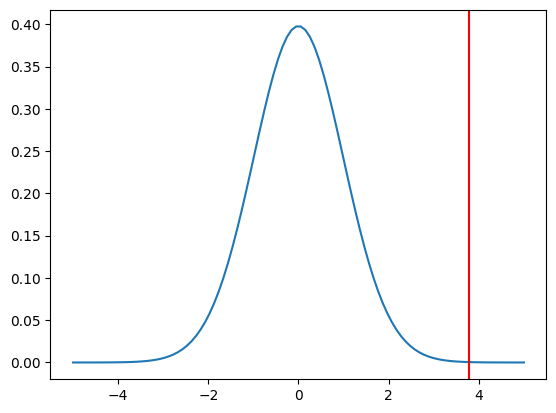

In [ ]:
from scipy.stats import t

# plotting the distribution of t test statistic along with the computed test statistic
# We are plotting the distributions here to better visualize the calculations
x = np.linspace(-5, 5, 100) # create an array of 100 numbers starting from -4 and ending at 4
plt.plot(x, t.pdf(x,df=len(df)-1)) # plot the pdf of the t distribution with n-1 degrees of freedom
plt.axvline(x = test_stat, c = 'r') # draw a vertical red line through the mentioned point
plt.show() # display the plot

**Step 7: Compare the p-value with $\alpha$**

In [ ]:
if p_value < 0.05:
    print(f'As the p-value {p_value} is less than the level of significance, we reject the null hypothesis.')
else:
    print(f'As the p-value {p_value} is greater than the level of significance, we fail to reject the null hypothesis.')

As the p-value 0.0001392381225166549 is less than the level of significance, we reject the null hypothesis.


**Step 8:  Draw inferences**

*Since this p-value is less than the significance level of 0.05, we reject the null hypothesis. This suggests that there is sufficient statistical evidence to conclude that users spend more time on the new landing page than on the existing landing page.*

## 2. Is the conversion rate (the proportion of users who visit the landing page and get converted) for the new page greater than the conversion rate for the old page?

**Step 1.  Perform Visual Analysis**

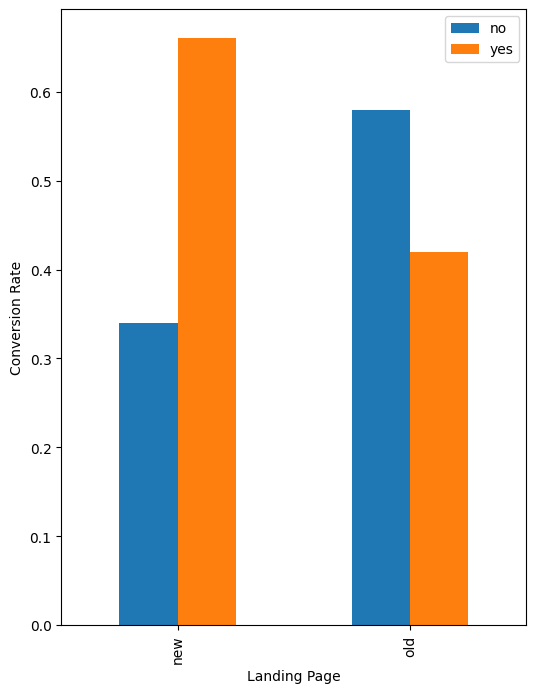

In [ ]:
pd.crosstab(df['landing_page'],df['converted'],normalize='index').plot(kind="bar", figsize=(6,8), stacked=False)
plt.legend()
plt.xlabel('Landing Page')
plt.ylabel('Conversion Rate')
plt.show()

**Step 2: Define the null and alternate hypothesis**

H$_o$: Conversion status is less than or equal to the conversion status for the old page.

H$_a$: Conversion status is greater than the conversion status for the old page.

**Step 3: Select Appropriate test - One-sided 2 proportion Z-test**

*Since we are asked to compare the populations of 2 categorical variables, the  one sided 2-proportion z-test will be used. The image below captures the path that is taken to get to the selected test.*

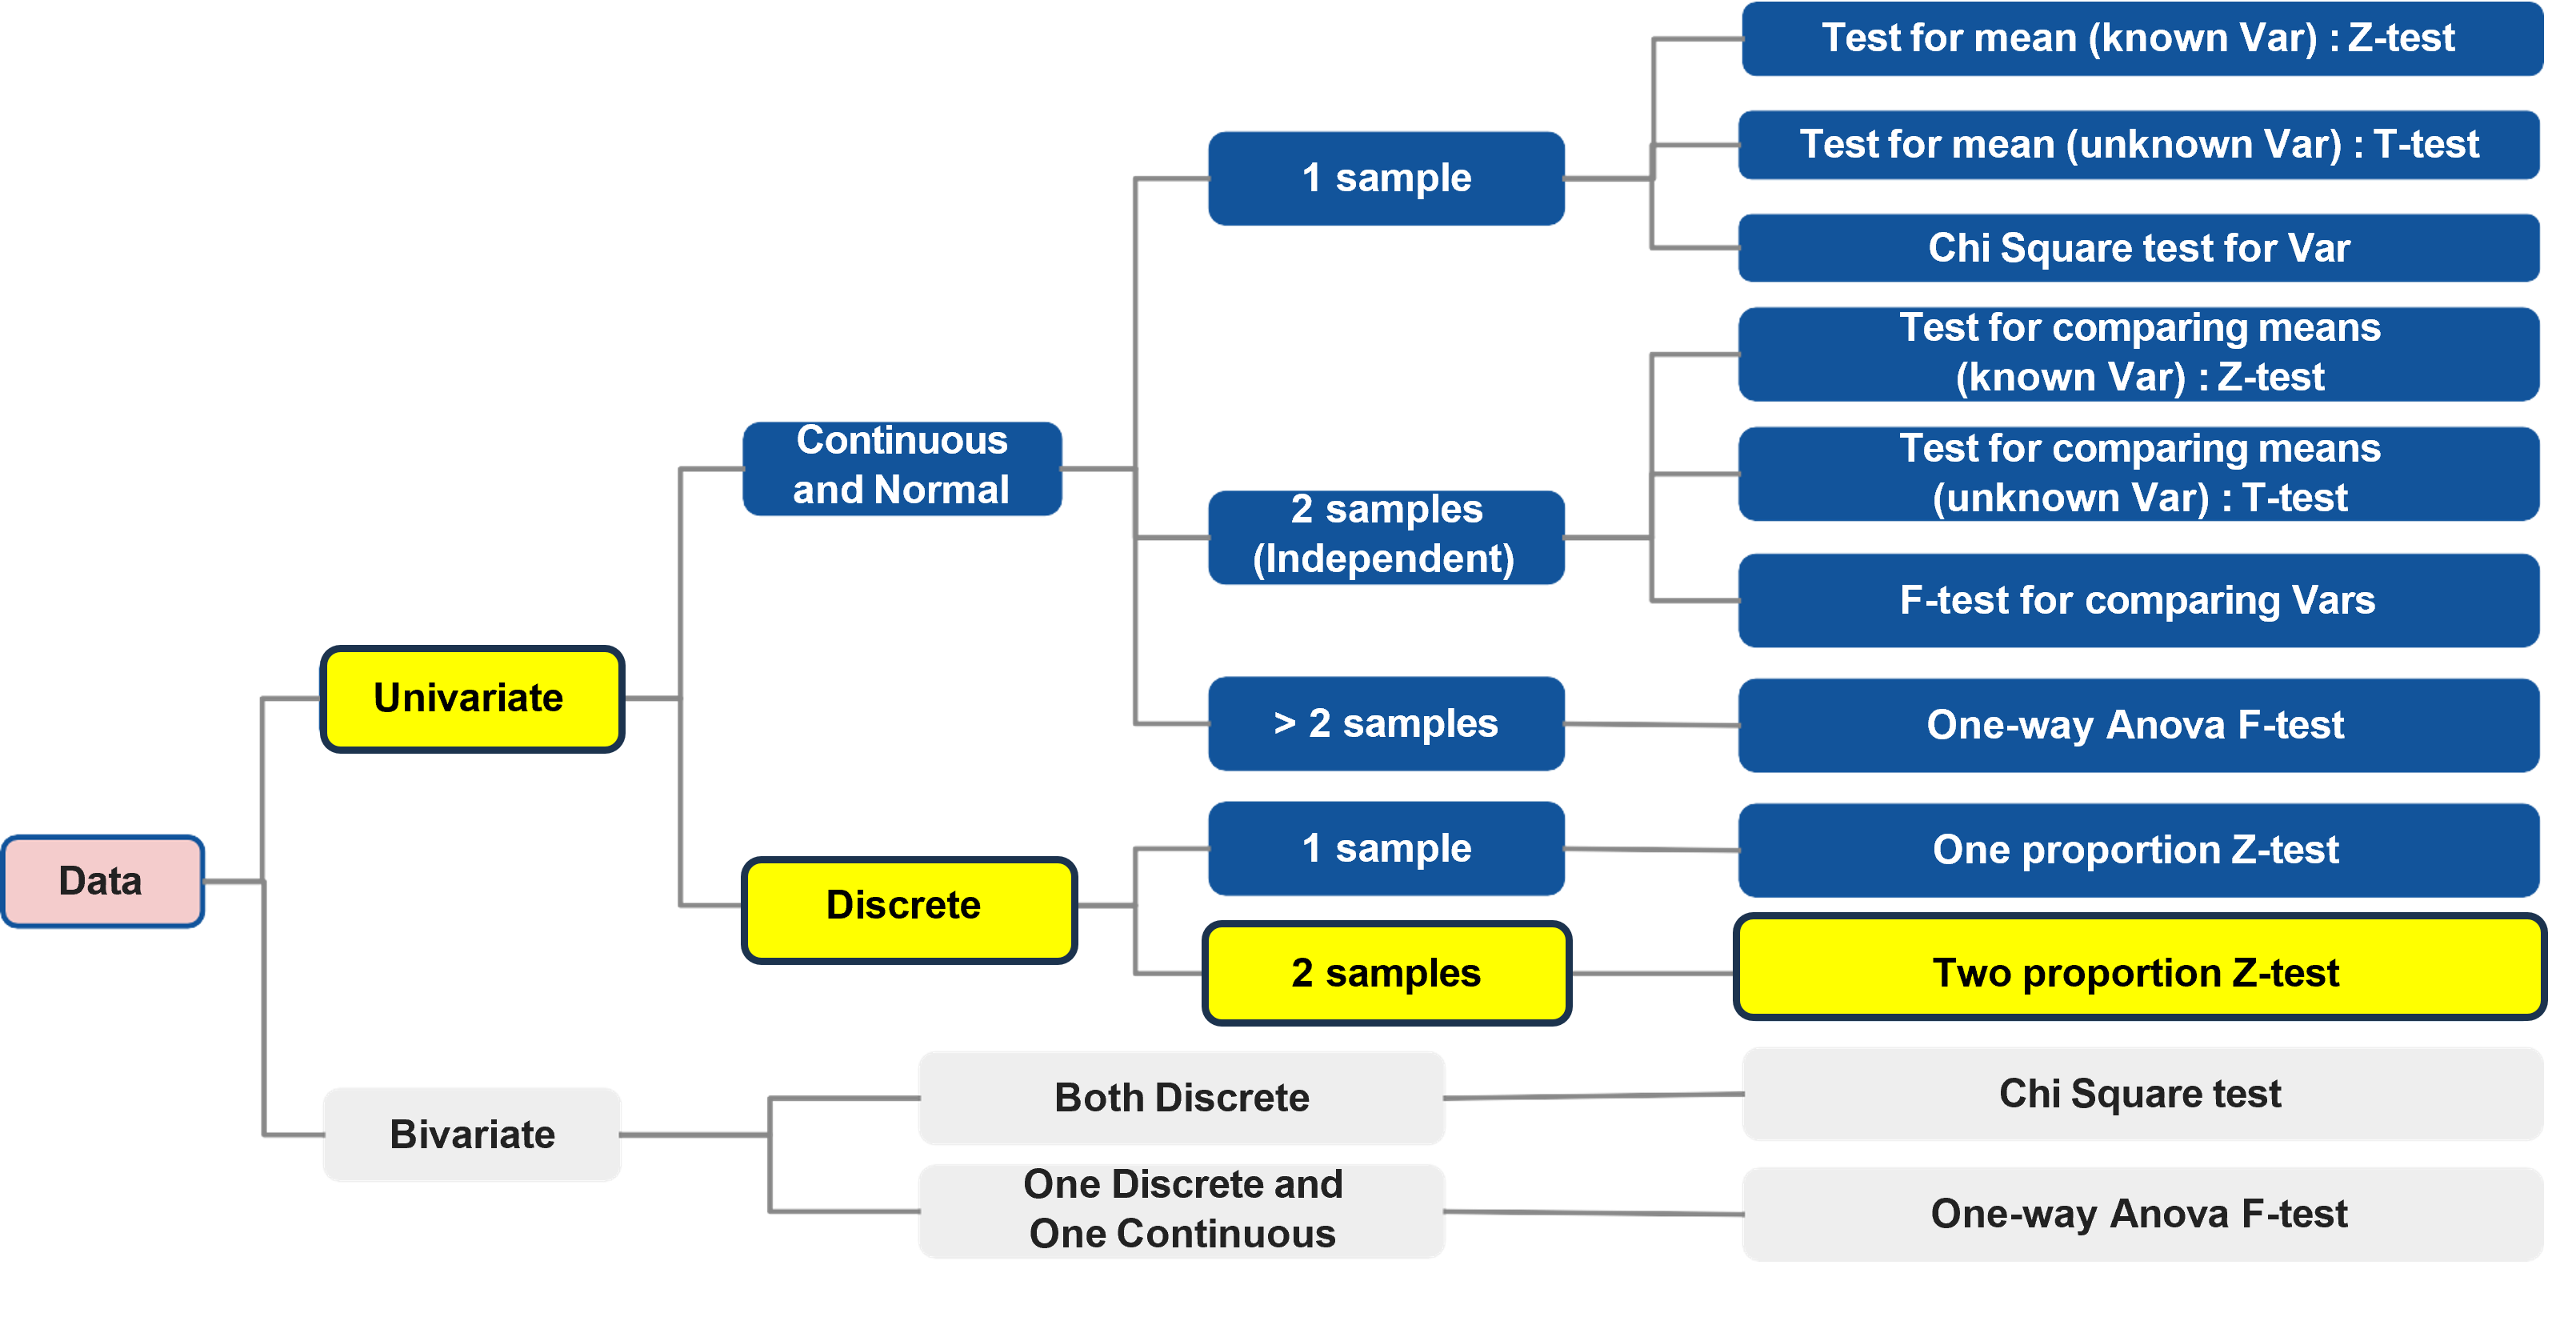

**Step 4: Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

**Step 5: Collect and prepare data**

Based on the business objective, the image below shows that the users into the two groups, treatment and control.

The existing landing page was served to the first group (control group) and the new landing page to the second group (treatment group).

Each group is divided into subgroups of whether a user decides to describe to the news portal (Yes) or not (No).

With this information we verbally state the following:

*   The proportion of users converted from the New Landing Page (Treatment Group) = 33/50.

*   The proportion of users converted from the Old Landing Page (Control Group) = 21/50.


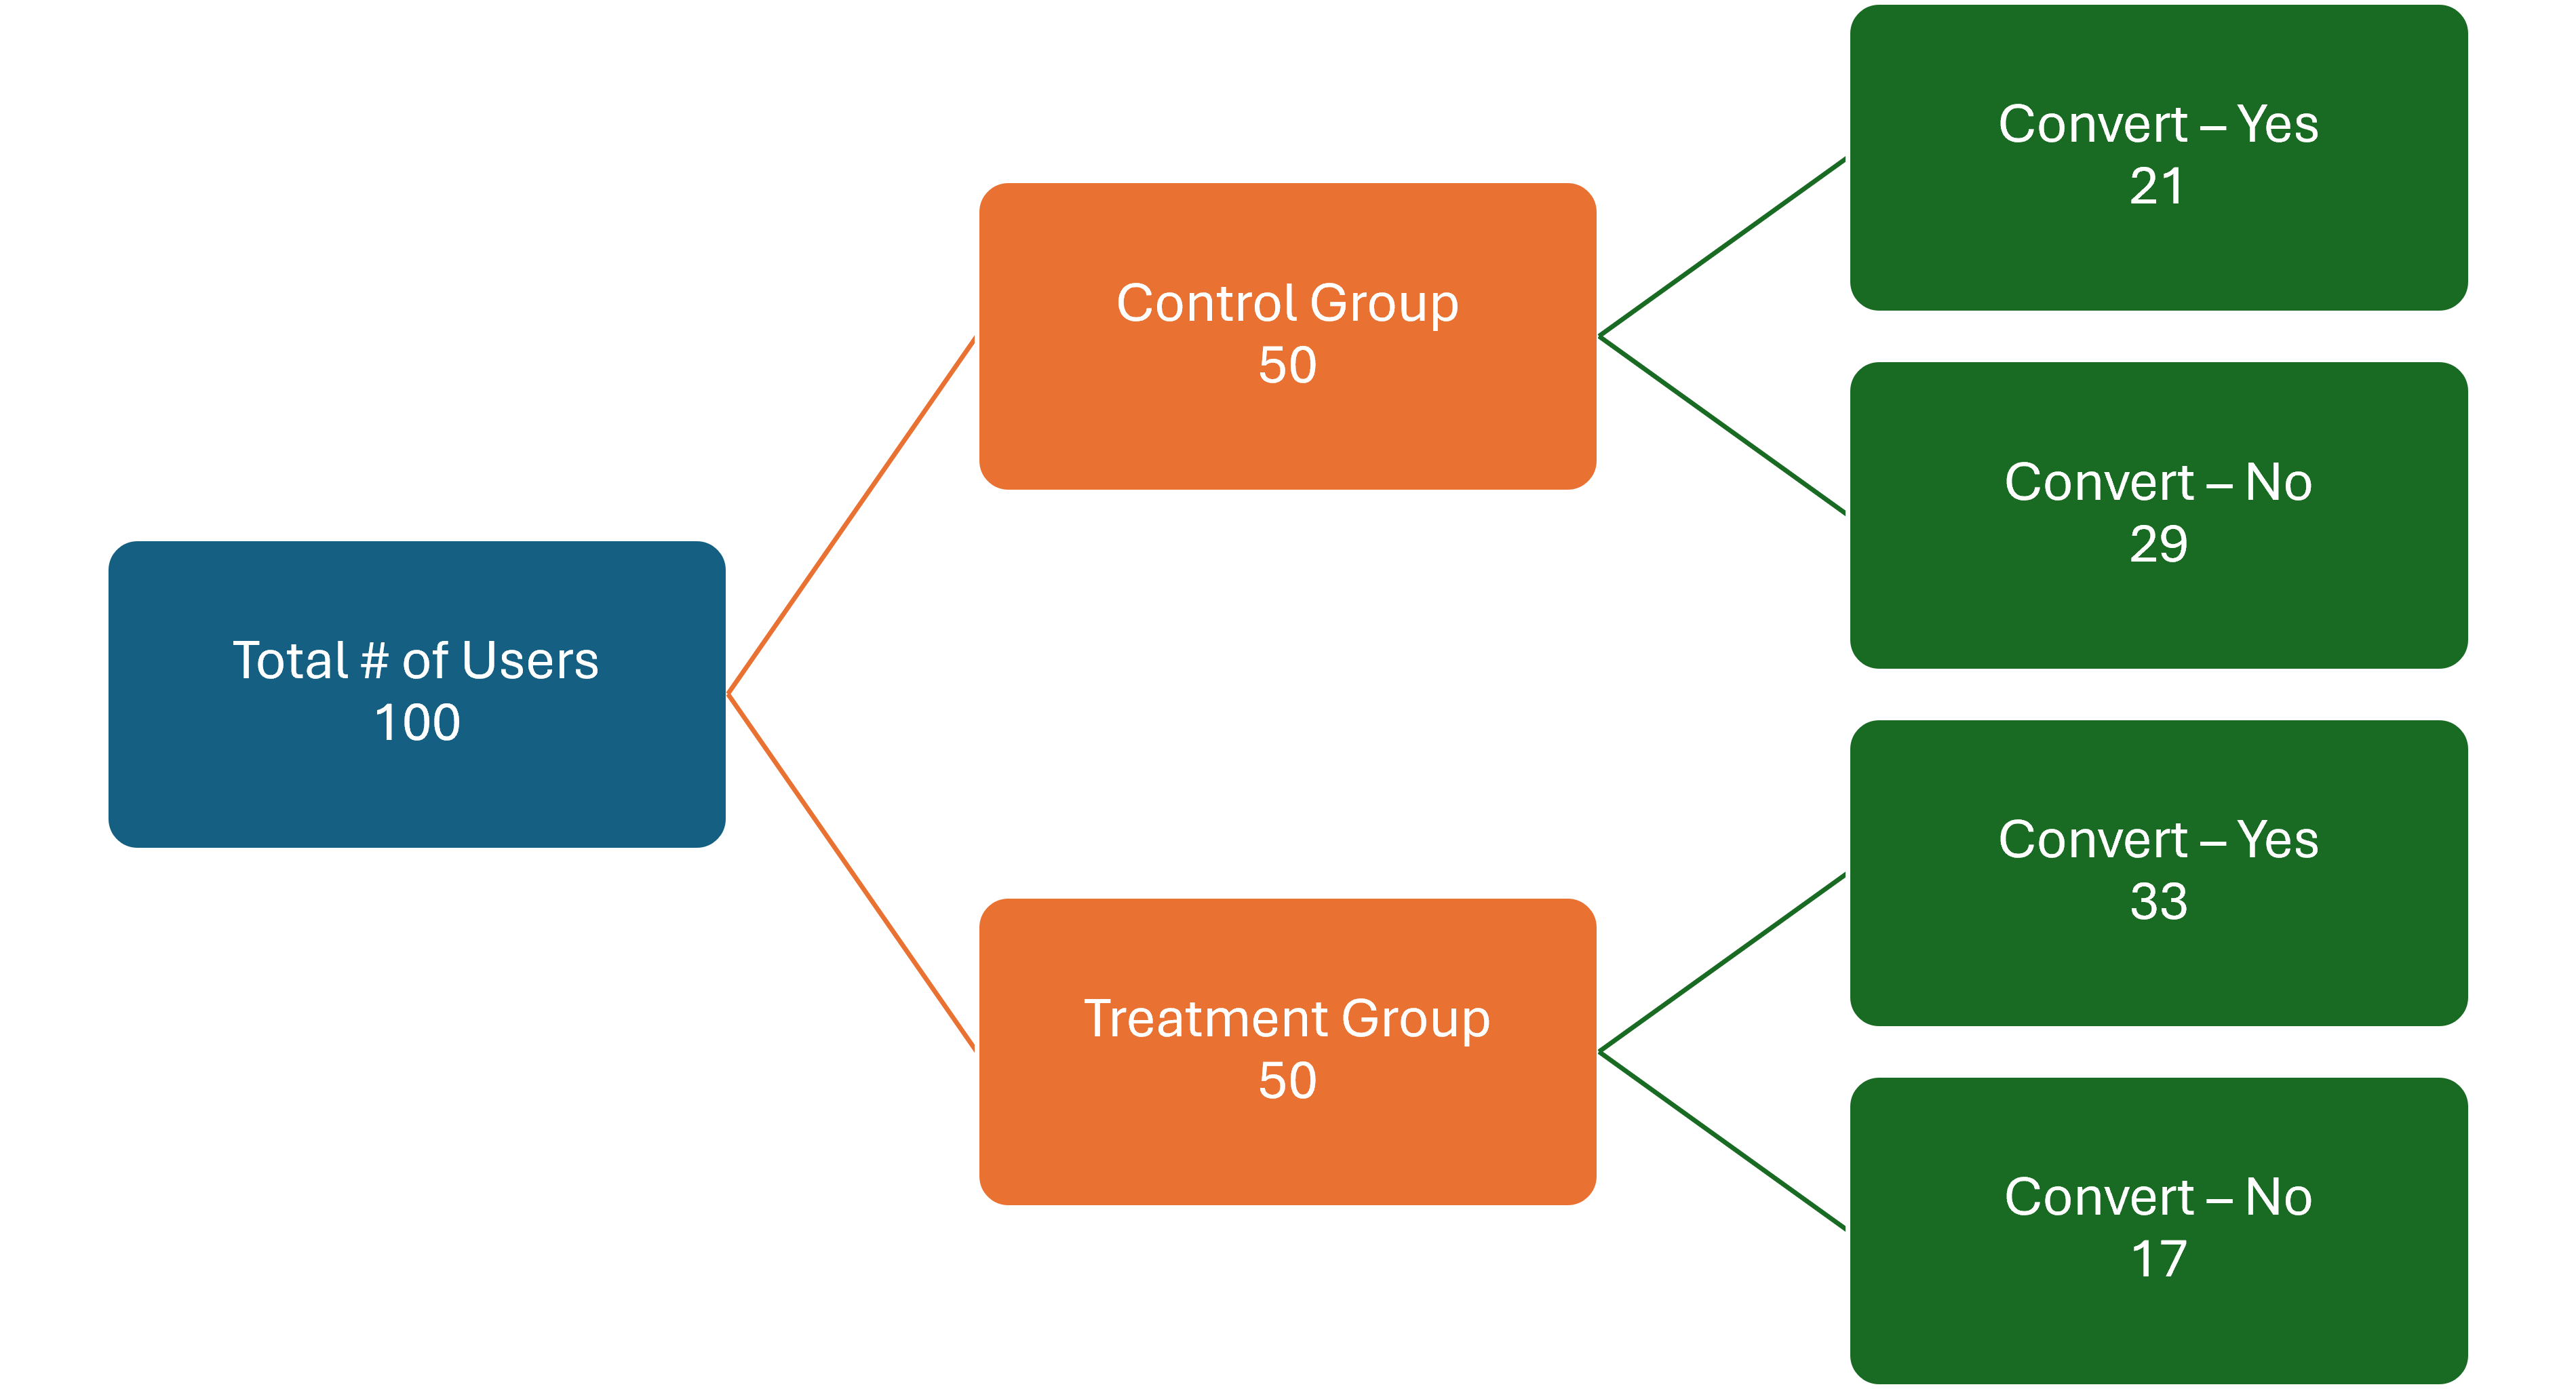

In [ ]:
# calculate the number of converted users in the treatment group
new_converted = df[df['group'] == 'treatment']['converted'].value_counts()['yes']

# calculate the number of converted users in the control group
old_converted = df[df['group'] == 'control']['converted'].value_counts()['yes']

n_control = df.group.value_counts()['control'] # total number of users in the control group
n_treatment = df.group.value_counts()['treatment'] # total number of users in the treatment group

print('The numbers of users served the new and old pages are {0} and {1} respectively.'.format(n_control, n_treatment ))

The numbers of users served the new and old pages are 50 and 50 respectively.


**Step 6: Calculate the p-value**

In [ ]:
# complete the code to import the required function
from statsmodels.stats.proportion import proportions_ztest

# write the code to calculate the p-value
test_stat, p_value = proportions_ztest([new_converted, old_converted] , [n_treatment, n_control], alternative = 'larger')   #complete the code by filling appropriate parameters in the blanks


print('The p-value is', p_value)

The p-value is 0.008026308204056278


**Step 7: Compare the p-value with $\alpha$**

In [ ]:
if p_value < 0.05:
    print(f'As the p-value {p_value} is less than the level of significance, we reject the null hypothesis.')
else:
    print(f'As the p-value {p_value} is greater than the level of significance, we fail to reject the null hypothesis.')

As the p-value 0.008026308204056278 is less than the level of significance, we reject the null hypothesis.


**Step 8:  Draw inferences**

*Since this p-value is less than the significance level of 0.05, we reject the null hypothesis. This suggests that there is sufficient statistical evidence to conclude that the conversion status (the proportion of users who visit the landing page and get converted) for the new page, is greater than the conversion status for the old page.*

## 3. Is the conversion and preferred language independent or related?

**Step 1.  Perform Visual Analysis**

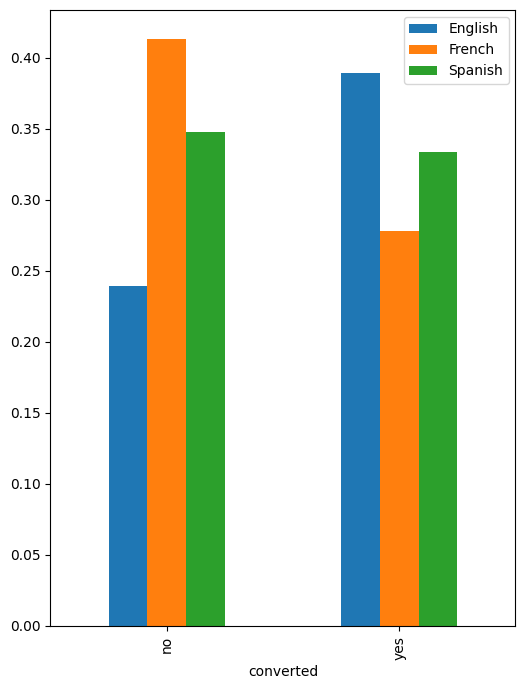

In [ ]:
pd.crosstab(df['converted'],df['language_preferred'],normalize='index').plot(kind="bar", figsize=(6,8), stacked=False)
plt.legend()
plt.show()

**Step 2: Define the null and alternate hypothesis**

H$_o$: Converted status does not depend on the preferred language.

H$_a$: Converted status does depend on the preferred language.



**Step 3: Select Appropriate test - Chi squared test**

*Since we are comparing two categorical variables which are descriptive, which will be bivariate, and both variables are discreet.  Therefore we will use the chi square test.*

**Step 4: Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

**Step 5: Collect and prepare data**

In [ ]:
# Use observed counts only; totals must not enter a chi-square test.
ct = pd.crosstab(df['language_preferred'], df['converted'])
ct

**Step 6: Calculate the p-value**

In [ ]:
from scipy.stats import chi2_contingency
# write the code to calculate the p-value
chi2, p_value, dof, exp_freq = chi2_contingency(ct)

print('The p-value is', p_value)
print('The chi2 is', chi2)
print('The degrees of freedom is', dof)
print('The expected frequencies are', exp_freq)



**Step 7: Compare the p-value with $\alpha$**

In [ ]:
# print the conclusion based on p-value
if p_value < 0.05:
    print(f'As the p-value {p_value} is less than the level of significance, we reject the null hypothesis.')
else:
    print(f'As the p-value {p_value} is greater than the level of significance, we fail to reject the null hypothesis.')

**Step 8:  Draw inferences**

*The corrected chi-square test gives p = 0.2130 (> 0.05). We fail to reject the null hypothesis. The sample does not provide sufficient evidence of an association between preferred language and conversion status; this does not establish that the variables are independent.*

## 4. Is the time spent on the new page same for the different language users?

**Step 1.  Perform Visual Analysis**

In [ ]:
#Create a new data frame and filter only users on the new landing page
new_page = df[df['landing_page'] == 'new']
new_page.head()

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
4,546459,treatment,new,4.75,yes,Spanish
6,546448,treatment,new,5.25,yes,French
8,546461,treatment,new,10.71,yes,French


The mean time spent on the new landing page for users who preferred Spanish is: 5.84
The mean time spent on the new landing page for users who preferred English is: 6.66
The mean time spent on the new landing page for users who preferred French  is: 6.2


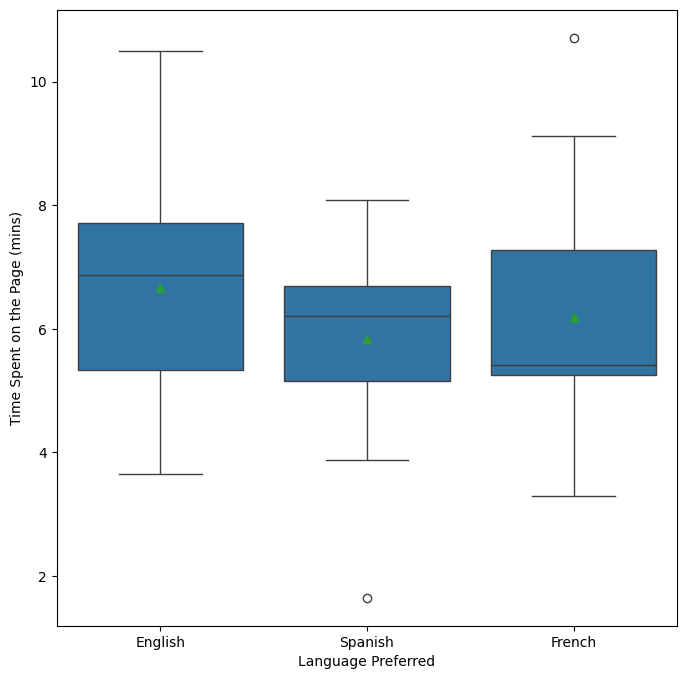

In [ ]:
# Create box plot to compare the means for each group
plt.figure(figsize=(8,8))
sns.boxplot(x = 'language_preferred', y = 'time_spent_on_the_page', showmeans = True, data = new_page)
plt.xlabel('Language Preferred')
plt.ylabel('Time Spent on the Page (mins)')
print('The mean time spent on the new landing page for users who preferred Spanish is:', round(new_page[new_page['language_preferred'] == 'Spanish']['time_spent_on_the_page'].mean(),2))
print('The mean time spent on the new landing page for users who preferred English is:', round(new_page[new_page['language_preferred'] == 'English']['time_spent_on_the_page'].mean(),2))
print('The mean time spent on the new landing page for users who preferred French  is:', round(new_page[new_page['language_preferred'] == 'French']['time_spent_on_the_page'].mean(),2))
plt.show()

*   The mean time spent on the new landing page for users who preferred English is approximately 6.66 minutes, which is the highest among the three languages.

*   Users who preferred French spent an average of 6.20 minutes on the new landing page.

*   Users who preferred Spanish spent an average of 5.84 minutes on the new landing page.

*   Visually, the box plot shows that while there are slight differences in the mean time spent, there is considerable overlap in the interquartile ranges (the middle 50% of data) for all three language groups, suggesting similar distributions of time spent.

*   The spread of time spent (variance) appears somewhat similar across all three languages, though English and French might show slightly wider distributions compared to Spanish.

**1. Shapiro Wilk Test**

**The Shapiro-Wilk test is chosen to check the assumption of normality for the time_spent_on_the_page data. This is typically done as a prerequisite before performing parametric tests like ANOVA, which assume that the data follows a normal distribution.**

**A. Define the null and alternate hypothesis**

H$_0$: The time spent on the new page follows a normal distribution.

H$_a$: The time spent on the new page does not follow a normal distribution.

**Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

In [ ]:
import scipy.stats as stats

# find the p-value
w, p_value = stats.shapiro(new_page['time_spent_on_the_page'])
print('The Shapiro Wilk p-value is', p_value)

The Shapiro Wilk p-value is 0.8040040364746845


**Compare the p-value with $\alpha$**

In [ ]:
# print the conclusion based on p-value
if p_value < 0.05:
    print(f'As the p-value {p_value} is less than the level of significance, we reject the null hypothesis.')
else:
    print(f'As the p-value {p_value} is greater than the level of significance, we fail to reject the null hypothesis.')

As the p-value 0.7970832186581234 is greater than the level of significance, we fail to reject the null hypothesis.


*Since the p-value of the test is greater than the 5% significance level, we fail to reject the null hypothesis that the response follows the normal distribution.*

**The Levene test will be used to check the equality of variances across the different language groups. This is an important assumption for the One-way ANOVA test, which wis used to compare the mean time spent on the new page by users of different preferred languages. By confirming equal variances (as indicated by our p-value being greater than 0.05), we ensure the validity of the ANOVA results.**

**2. Levene Test**

In [ ]:
dataset = new_page.groupby('language_preferred')['time_spent_on_the_page'].agg(['sum','mean', 'std'])
dataset.columns = ['Total Time', 'Average Time (Mean)', 'Standard Deviation']
dataset

**Define the null and alternate hypothesis**

H$_0$: The population variances are equal.

H$_a$: The population variance for at least one of the population variance is different from the rest.

**Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

In [ ]:
from scipy.stats import levene
import scipy.stats as stats

# Extract time spent for each language group from the new_page DataFrame
english_time = new_page[new_page['language_preferred'] == 'English']['time_spent_on_the_page']
french_time = new_page[new_page['language_preferred'] == 'French']['time_spent_on_the_page']
spanish_time = new_page[new_page['language_preferred'] == 'Spanish']['time_spent_on_the_page']

In [ ]:
# Perform Levene's test for equality of variances
levene_stat, levene_p_value = stats.levene(english_time, french_time, spanish_time)
print(f'Levene test p-value: {levene_p_value:.3f}')

**Compare the p-value with $\alpha$**

In [ ]:
# print the conclusion based on p-value
if p_value < 0.05:
    print(f'As the p-value {p_value:.3f} is less than the level of significance (0.05), we reject the null hypothesis.')
else:

    print(f'As the p-value {p_value:.3f} is greater than the level of significance (0.05), we fail to reject the null hypothesis.')

Since this p-value is more than the significance level of 0.05, we fail to reject the null hypothesis. This suggests that there is not sufficient statistical evidence to conclude that the time spent on the new page is the same for the different language users.

**3. One-way ANOVA Test**

The One-way ANOVA test will be used to assess whether the mean time spent on the new landing page is the same for users who prefer English, French, and Spanish. It helps us compare if these language groups exhibit similar average engagement times or if at least one group's average time is significantly different from the others.

**Step 2: Define the null and alternate hypothesis**

H$_0$: $\mu_{\text{English}} = \mu_{\text{French}} = \mu_{\text{Spanish}}$ (The mean time spent on the new page is the same for all language users.)

H$_a$: $\mu_{\text{English}} = \mu_{\text{French}} \neq\mu_{\text{Spanish}}$ (The mean time spent on the new page is not the same for at least one preferred language user.)

**Step 4: Decide the significance level**

*The significance level is $\alpha$ = 0.05 (based on the given information in the problem statement).*

In [ ]:
from scipy.stats import f_oneway
import scipy.stats as stats

# Extract time spent for each language group from the new_page DataFrame
english_time = new_page[new_page['language_preferred'] == 'English']['time_spent_on_the_page']
french_time = new_page[new_page['language_preferred'] == 'French']['time_spent_on_the_page']
spanish_time = new_page[new_page['language_preferred'] == 'Spanish']['time_spent_on_the_page']

In [ ]:
# perform one-way ANOVA test
fvalue, p_value = stats.f_oneway(english_time, french_time, spanish_time)


# print the p-value
print('The ANOVA one-way test p-value is', p_value)

**Compare the p-value with $\alpha$**

In [ ]:
# print the conclusion based on p-value
if p_value < 0.05:
    print(f'As the p-value {p_value:.3f} is less than the level of significance (0.05), we reject the null hypothesis.')
else:

    print(f'As the p-value {p_value:.3f} is greater than the level of significance (0.05), we fail to reject the null hypothesis.')

**Draw inferences**

*Since this p-value is more than the significance level of 0.05, we fail to reject the null hypothesis. This suggests that time spent on the new page is the same for the different language users.*

## Conclusion and Business Recommendations

### **Conclusion**

Based on the analysis of the A/B test data, the following conclusions can be drawn at a 5% significance level:

1.  **Users spend more time on the new landing page:** The statistical analysis showed significant evidence that users spend more time on the new landing page compared to the old one.
2.  **Higher conversion rate for the new page:** The new landing page has a significantly higher conversion rate (proportion of users who subscribe) than the old landing page.
3.  **Converted status is independent of preferred language:** There is no statistical evidence to suggest that a user's conversion status depends on their preferred language (English, French, or Spanish).
4.  **Time spent on the new page is similar across language users:** There is no significant difference in the mean time spent on the new landing page among users who preferred different languages.

### **Business Recommendations**

Based on the conclusions, here are some business recommendations for E-news Express:

1.  **Implement the new landing page:** Given that the new landing page leads to both increased time spent by users and a higher conversion rate, it is strongly recommended to fully roll out the new landing page to all users.
2.  **Maintain multilingual support:** Since preferred language does not significantly impact conversion rates or time spent on the new page, E-news Express should continue to support English, French, and Spanish to cater to its diverse user base.
3.  **Further optimization of the new page:** While the new page is performing well, continuous A/B testing can be conducted on various elements within the new page (e.g., different headlines, call-to-action buttons, content layouts) to further optimize user engagement and conversion.
4.  **Explore other conversion drivers:** As language is not a significant factor in conversion, E-news Express could explore other potential factors such as user demographics, traffic source, or device type to identify additional opportunities for improving subscription rates.